In [1]:
import lseg.data as ld
from datetime import datetime

In [2]:
import lseg.data as ld
from datetime import datetime

APP_KEY = "977f2ae864cc4df38f56cda0e9e093304f8eaccd"
USERNAME = "enegade68@servicio.tec.mx"
PASSWORD = "Jesuifrancois123"

session = ld.session.platform.Definition(
    app_key=APP_KEY,
    grant=ld.session.platform.GrantPassword(
        username=USERNAME,
        password=PASSWORD
    ),
    signon_control=True
).get_session()

session.open()
ld.session.set_default(session)

print("Estado:", session.open_state)
print("Hora:", datetime.now())

/Users/francoflores/lseg-project/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35:NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020


Estado: OpenState.Opened
Hora: 2026-10-20 20:56:56.007367


In [3]:
test = ld.get_data(
    universe=["CAT"],
    fields=[
        "TR.CommonName",
        "TR.PriceClose",
        "TR.Volume",
        "TR.CompanyMarketCap"
    ]
)

test

,Instrument,Company Common Name,Price Close,Volume,Company Market Cap
0,CAT,Caterpillar Inc,725.24,2656291,333374616498.359985


VRT US  spot = 203.56   (20-Oct-2026 22:57 NY)


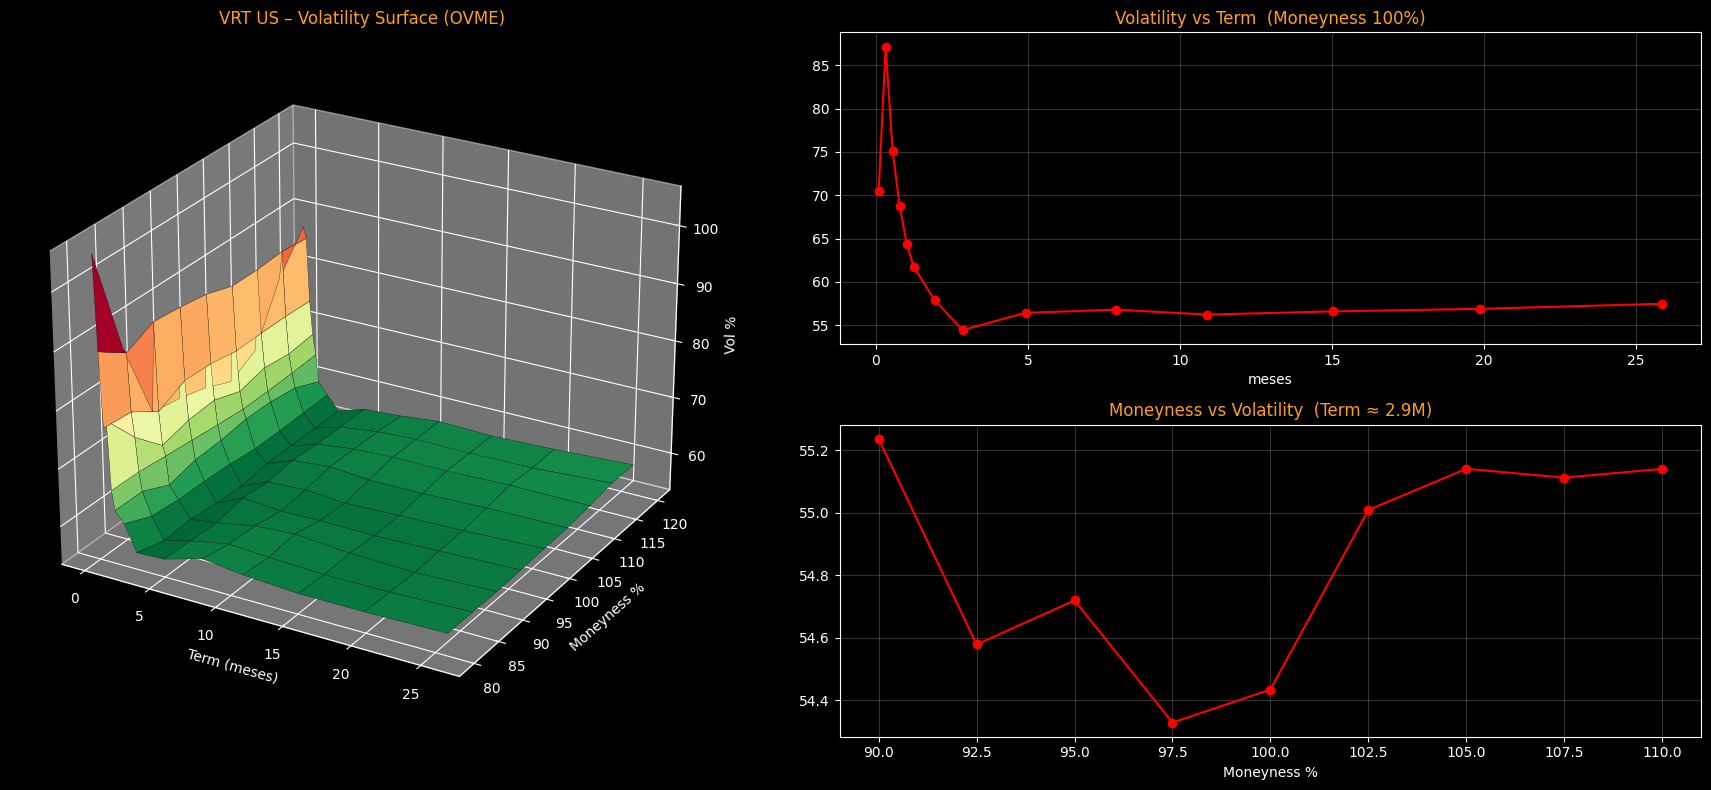


=== PRICING  VRT US  | expiry 23-Oct-2026  | T = 2.71 días ===
                 Leg 1: Sell C  Leg 2: Buy P  Leg 3: Buy C      TOTAL
Strike                235.0000      217.5000      237.5000        NaN
Vol                    79.6211       69.8144      116.9702        NaN
Price/Share             0.0991       14.7631        0.6081        NaN
Leg Prc (Total)        -9.9053     1476.3074       60.8146  1527.2168
Delta (%)              -1.9976      -85.8425        7.1622   -80.6779
Gamma (%)              -0.7958        3.9765        1.7625     4.9432
Vega                   -0.9203        4.1174        2.5155     5.7126
Theta                   8.3553      -47.0630      -42.5676   -81.2754
Rho                    -0.0291       -1.0230        0.1007    -0.9514
Time Value             -9.9053       82.3072       60.8146   133.2166


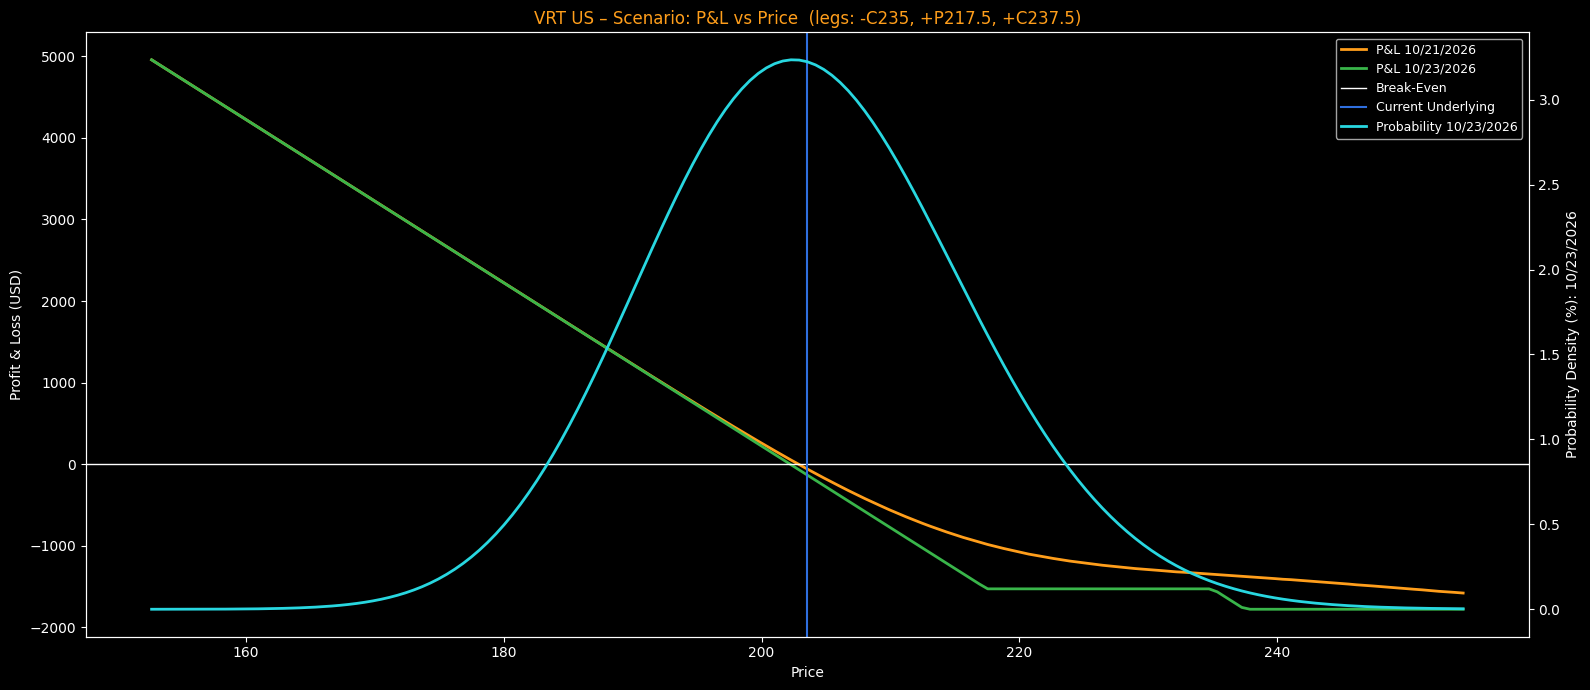


=== MATRIX  (Y: strikes escalados %, X: vencimiento) ===
                              1M       2M       3M       4M       5M       6M
Moneyness Output                                                             
100       Price (Total)  2261.41  2588.84  2897.51  3266.40  3567.77  3829.51
          Delta           -60.36   -56.20   -53.65   -50.94   -51.80   -49.07
105       Price (Total)  3054.77  3354.74  3636.13  3955.10  4224.53  4488.30
          Delta           -70.37   -68.20   -63.59   -56.83   -57.46   -53.27
110       Price (Total)  3935.91  4185.05  4437.58  4760.95  5037.98  5291.55
          Delta           -80.41   -70.49   -69.72   -62.46   -61.36   -55.56
115       Price (Total)  4878.02  5080.46  5312.25  5576.58  5810.56  6045.52
          Delta           -84.67   -78.85   -73.67   -68.03   -65.41   -63.33
120       Price (Total)  5875.43  6028.57  6212.16  6464.50  6697.01  6902.16
          Delta           -90.19   -84.42   -78.41   -74.44   -67.72   -66.58
125   

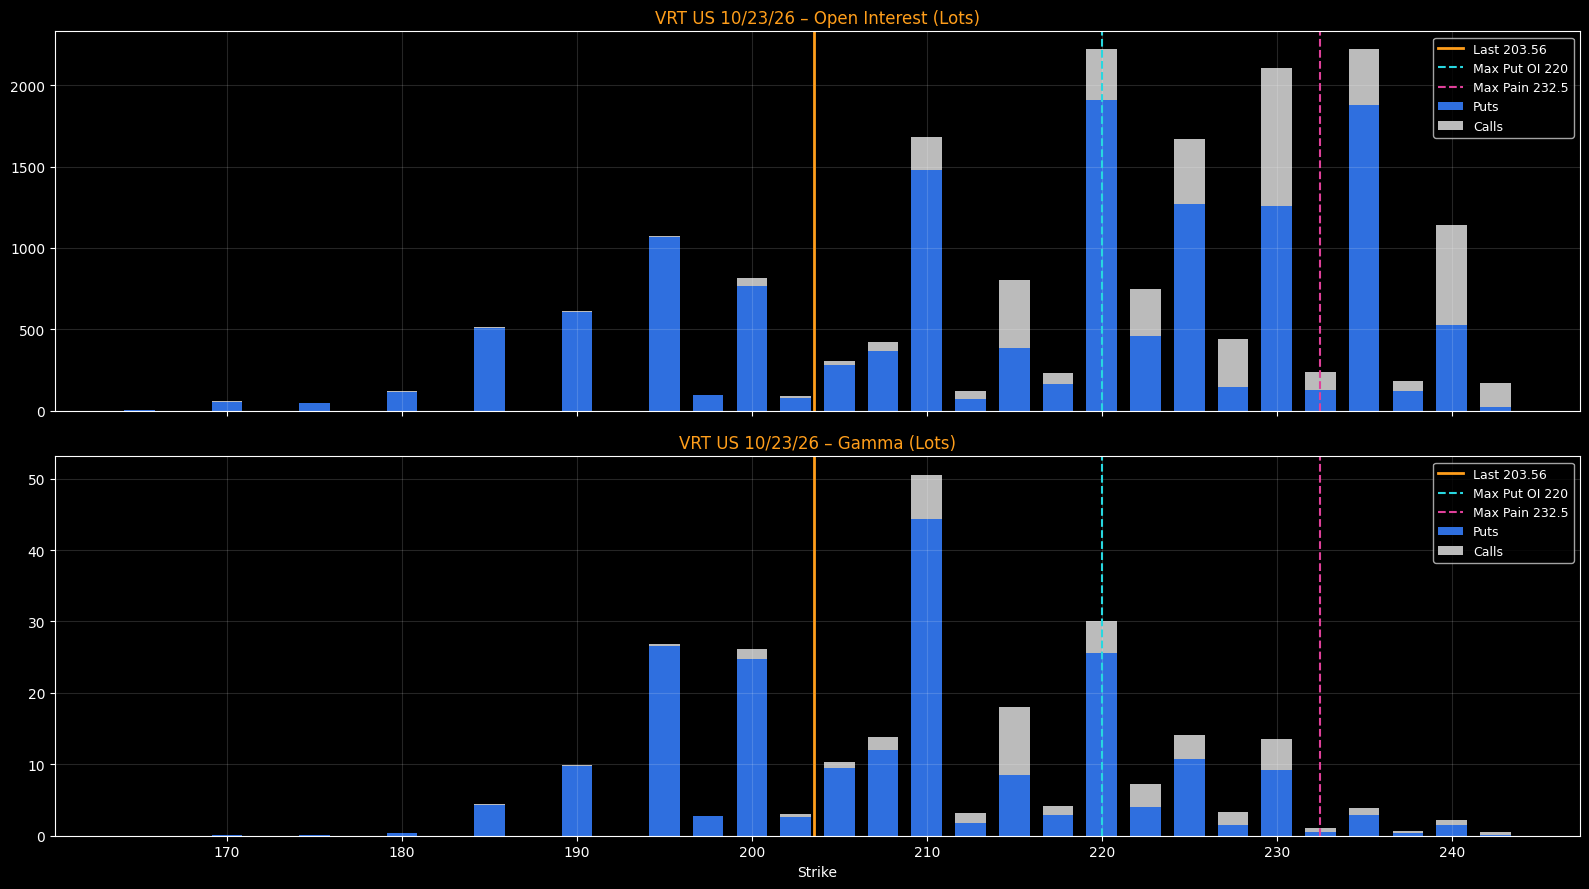

                Ticker  Last Px    Mny  Vol (Lots)  OI (Lots)  Vol/OI  %TotOI  Delta (Lots)  Gamma (Lots)    IV
  VRT US 10/23/26 P220    17.25 108.08        72.0       1911    0.04    6.45      -1761.34         25.62 62.21
  VRT US 10/23/26 P235    31.33 115.45        57.0       1881    0.03    6.35      -1869.02          2.91 66.02
  VRT US 10/23/26 P210     8.72 103.16        82.0       1479    0.06    4.99      -1027.15         44.36 66.63
  VRT US 10/23/26 P225    21.84 110.53        25.0       1269    0.02    4.28      -1206.32         10.72 68.95
  VRT US 10/23/26 P230    26.56 112.99        62.0       1257    0.05    4.24      -1187.77          9.23 86.47
  VRT US 10/23/26 P195     1.75  95.79       163.0       1067    0.15    3.60       -236.28         26.58 68.02
  VRT US 10/23/26 C230     0.14 112.99        66.0        851    0.08    2.87         23.93          4.29 72.85
  VRT US 10/23/26 P200     3.41  98.25       437.0        769    0.57    2.60       -282.04         24.7

In [5]:
# =====================================================================
#  VRT US Equity – réplica estilo Bloomberg (OVME / OMON / OPX) en Colab
#  1) Superficie de volatilidad + Vol vs Term + Moneyness vs Vol
#  2) Pricing de estrategia de 3 patas (americanas, CRR) con griegas
#  3) Scenario: P&L vs precio + densidad de probabilidad
#  4) Matrix: precio y delta por moneyness x vencimiento
#  5) Option Expiration: Open Interest, Gamma, Max Pain, P/C ratios
#  En Colab, corre primero:   !pip install -q yfinance
# =====================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import norm
from scipy.optimize import brentq
import yfinance as yf

plt.style.use("dark_background")
ORANGE, BLUE, GREEN, CYAN = "#ff9e1b", "#2f6fdf", "#39b54a", "#28d7e0"
pd.set_option("display.width", 200, "display.max_columns", 30)

# ------------------------- PARÁMETROS --------------------------------
TICKER   = "VRT"
R        = 0.04      # tasa libre de riesgo (Bloomberg usó 0% MMkt en el ejercicio)
Q        = 0.0       # dividend yield
MAX_EXP  = 14        # vencimientos a descargar
EXPIRY   = None      # None = vencimiento más cercano (como OPX 16-Oct-26) o "2026-10-16"
# Estrategia del ejercicio (GLW): Sell Call 115.34%, Buy Put 106.47%, Buy Call 117.11%
# Se reescala al spot de VRT y se ajusta al strike listado más cercano.
LEGS = [
    dict(type="C", side=-1, pct=115.34, shares=100),
    dict(type="P", side=+1, pct=106.47, shares=100),
    dict(type="C", side=+1, pct=117.11, shares=100),
]
NOW = pd.Timestamp.now(tz="America/New_York").tz_localize(None)


# ------------------------- 1. DATOS ----------------------------------
def load_chain(ticker=TICKER, max_exp=MAX_EXP):
    tk = yf.Ticker(ticker)
    spot = float(tk.history(period="5d")["Close"].iloc[-1])
    frames = []
    for exp in tk.options[:max_exp]:
        ch = tk.option_chain(exp)
        for typ, d in (("C", ch.calls), ("P", ch.puts)):
            d = d[["strike", "bid", "ask", "lastPrice", "volume", "openInterest", "impliedVolatility"]].copy()
            d["type"], d["expiry"] = typ, pd.Timestamp(exp) + pd.Timedelta(hours=16)
            frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    df[["volume", "openInterest"]] = df[["volume", "openInterest"]].fillna(0)
    df["spot"] = spot
    df["t"] = (df["expiry"] - NOW).dt.total_seconds() / (365 * 86400)
    df["mid"] = np.where((df.bid > 0) & (df.ask > df.bid), (df.bid + df.ask) / 2, df.lastPrice)
    return df[df.t > 0].reset_index(drop=True), spot


# ------------------------- 2. MODELOS --------------------------------
def bs_price(S, K, t, vol, typ, r=R, q=Q):
    sd = vol * np.sqrt(t)
    d1 = (np.log(S / K) + (r - q) * t) / sd + 0.5 * sd
    d2 = d1 - sd
    if typ == "C":
        return S * np.exp(-q * t) * norm.cdf(d1) - K * np.exp(-r * t) * norm.cdf(d2)
    return K * np.exp(-r * t) * norm.cdf(-d2) - S * np.exp(-q * t) * norm.cdf(-d1)


def bs_gamma(S, K, t, vol, r=R, q=Q):
    sd = vol * np.sqrt(t)
    d1 = (np.log(S / K) + (r - q) * t) / sd + 0.5 * sd
    return np.exp(-q * t) * norm.pdf(d1) / (S * sd)


def bs_delta(S, K, t, vol, typ, r=R, q=Q):
    sd = vol * np.sqrt(t)
    d1 = (np.log(S / K) + (r - q) * t) / sd + 0.5 * sd
    return np.exp(-q * t) * (norm.cdf(d1) if typ == "C" else norm.cdf(d1) - 1)


def implied_vol(price, S, K, t, typ):
    lo = max(bs_price(S, K, t, 1e-4, typ), 0)
    hi = bs_price(S, K, t, 5.0, typ)
    if not (lo < price < hi):
        return np.nan
    return brentq(lambda v: bs_price(S, K, t, v, typ) - price, 1e-4, 5.0)


def crr_american(S, K, T, vol, typ, r=R, q=Q, N=200):
    """Árbol binomial CRR para opción americana; S puede ser vector."""
    S = np.atleast_1d(np.asarray(S, float))
    pay = (lambda x: np.maximum(x - K, 0)) if typ == "C" else (lambda x: np.maximum(K - x, 0))
    if T <= 1e-8:
        return pay(S)
    dt = T / N
    u = np.exp(vol * np.sqrt(dt)); d = 1 / u
    p = (np.exp((r - q) * dt) - d) / (u - d); disc = np.exp(-r * dt)
    j = np.arange(N + 1)
    ST = S[:, None] * u ** (N - j) * d ** j
    V = pay(ST)
    for _ in range(N):
        V = disc * (p * V[:, :-1] + (1 - p) * V[:, 1:])
        ST = ST[:, :-1] * d
        V = np.maximum(V, pay(ST))
    return V[:, 0]


# ------------------------- 3. SUPERFICIE -----------------------------
chain, SPOT = load_chain()
print(f"{TICKER} US  spot = {SPOT:,.2f}   ({NOW:%d-%b-%Y %H:%M} NY)")

F = SPOT * np.exp((R - Q) * chain.t)
otm = chain[((chain.type == "P") & (chain.strike < F)) | ((chain.type == "C") & (chain.strike >= F))].copy()
otm["vol"] = [implied_vol(p, SPOT, k, t, ty) for p, k, t, ty in zip(otm.mid, otm.strike, otm.t, otm.type)]
otm["vol"] = otm["vol"].fillna(otm["impliedVolatility"].where(otm.impliedVolatility > 0.01))
otm["mny"] = otm.strike / SPOT
otm = otm[otm.mny.between(0.6, 1.5) & otm.vol.between(0.02, 3)].dropna(subset=["vol"])

smiles = {t: g.sort_values("mny") for t, g in otm.groupby("t") if len(g) >= 4}
TERMS = np.array(sorted(smiles))


def smile_vol(t, m):
    g = smiles[t]
    return np.interp(m, g.mny, g.vol)          # extrapolación plana en los extremos


def surf_vol(m, T):
    """Vol en moneyness m (K/S) y plazo T, interpolando varianza total entre vencimientos."""
    w = np.array([smile_vol(t, m) ** 2 * t for t in TERMS])
    if T <= TERMS[0]:
        return smile_vol(TERMS[0], m)
    if T >= TERMS[-1]:
        return smile_vol(TERMS[-1], m)
    return np.sqrt(np.interp(T, TERMS, w) / T)


MNY = np.arange(0.80, 1.2001, 0.05)
Z = np.array([[smile_vol(t, m) * 100 for m in MNY] for t in TERMS])

fig = plt.figure(figsize=(18, 8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
Tg, Mg = np.meshgrid(TERMS * 12, MNY * 100, indexing="ij")
ax.plot_surface(Tg, Mg, Z, cmap=cm.RdYlGn_r, edgecolor="k", linewidth=0.2)
ax.set_xlabel("Term (meses)"); ax.set_ylabel("Moneyness %"); ax.set_zlabel("Vol %")
ax.set_title(f"{TICKER} US – Volatility Surface (OVME)", color=ORANGE)
ax.view_init(elev=25, azim=-60)

ax2 = fig.add_subplot(2, 2, 2)
atm = [smile_vol(t, 1.0) * 100 for t in TERMS]
ax2.plot(TERMS * 12, atm, "o-", color="red"); ax2.grid(alpha=0.2)
ax2.set_title("Volatility vs Term  (Moneyness 100%)", color=ORANGE); ax2.set_xlabel("meses")

ax3 = fig.add_subplot(2, 2, 4)
t3m = TERMS[np.argmin(abs(TERMS - 0.25))]
m_ax = np.arange(0.90, 1.1001, 0.025)
ax3.plot(m_ax * 100, [smile_vol(t3m, m) * 100 for m in m_ax], "o-", color="red"); ax3.grid(alpha=0.2)
ax3.set_title(f"Moneyness vs Volatility  (Term ≈ {t3m*12:.1f}M)", color=ORANGE); ax3.set_xlabel("Moneyness %")
plt.tight_layout(); plt.show()


# ------------------------- 4. PRICING (3 patas) ----------------------
exp_list = sorted(chain.expiry.unique())
EXP = pd.Timestamp(EXPIRY) + pd.Timedelta(hours=16) if EXPIRY else exp_list[0]
T_EXP = (EXP - NOW).total_seconds() / (365 * 86400)
strikes_exp = np.sort(chain[chain.expiry == EXP].strike.unique())
for L in LEGS:
    L["K"] = float(strikes_exp[np.argmin(abs(strikes_exp - SPOT * L["pct"] / 100))])
    L["vol"] = float(surf_vol(L["K"] / SPOT, T_EXP))


def leg_metrics(L, S=SPOT, T=T_EXP, vol=None, K=None):
    K = K or L["K"]; v = vol or L["vol"]; h = S * 0.005
    P = lambda s=S, t=T, vv=v, r=R: crr_american(s, K, t, vv, L["type"], r=r)[0]
    p0, pu, pd_ = P(), P(S + h), P(S - h)
    intrinsic = max(S - K, 0) if L["type"] == "C" else max(K - S, 0)
    m = L["side"] * L["shares"]
    return dict(Strike=K, Vol=v * 100, **{
        "Price/Share": p0, "Leg Prc (Total)": m * p0,
        "Delta (%)": L["side"] * (pu - pd_) / (2 * h) * 100,
        "Gamma (%)": L["side"] * (pu - 2 * p0 + pd_) / h**2 * S / 100 * 100,
        "Vega": m * (P(vv=v + 0.01) - p0),
        "Theta": m * (P(t=max(T - 1 / 365, 0)) - p0),
        "Rho": m * (P(r=R + 0.01) - p0),
        "Time Value": m * (p0 - intrinsic)})


pricing = pd.DataFrame({f"Leg {i+1}: {'Buy' if L['side']>0 else 'Sell'} {L['type']}": leg_metrics(L)
                        for i, L in enumerate(LEGS)})
pricing["TOTAL"] = pricing.iloc[2:].sum(axis=1)
pricing.loc[["Strike", "Vol", "Price/Share"], "TOTAL"] = np.nan
print(f"\n=== PRICING  {TICKER} US  | expiry {EXP:%d-%b-%Y}  | T = {T_EXP*365:.2f} días ===")
print(pricing.round(4).to_string())
PREMIUM = pricing.loc["Leg Prc (Total)", "TOTAL"]


# ------------------------- 5. SCENARIO -------------------------------
prices = np.linspace(SPOT * 0.75, SPOT * 1.25, 161)
fig, ax = plt.subplots(figsize=(16, 7))
dates = [(NOW + pd.Timedelta(days=1)).normalize() + pd.Timedelta(hours=16), EXP]
for dte, col in zip(dates, [ORANGE, GREEN]):
    T_left = max((EXP - dte).total_seconds() / (365 * 86400), 0)
    val = sum(L["side"] * L["shares"] * crr_american(prices, L["K"], T_left, L["vol"], L["type"]) for L in LEGS)
    ax.plot(prices, val - PREMIUM, color=col, lw=2, label=f"P&L {dte:%m/%d/%Y}")
ax.axhline(0, color="white", lw=1, label="Break-Even")
ax.axvline(SPOT, color=BLUE, lw=1.5, label="Current Underlying")
ax.set_xlabel("Price"); ax.set_ylabel("Profit & Loss (USD)")
axp = ax.twinx()
vol_atm = surf_vol(1.0, T_EXP); Fwd = SPOT * np.exp((R - Q) * T_EXP)
sd = vol_atm * np.sqrt(T_EXP); mu = np.log(Fwd) - 0.5 * sd**2
pdf = norm.pdf((np.log(prices) - mu) / sd) / (prices * sd)
axp.plot(prices, pdf * 100, color=CYAN, lw=2, label=f"Probability {EXP:%m/%d/%Y}")
axp.set_ylabel(f"Probability Density (%): {EXP:%m/%d/%Y}")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axp.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
ax.set_title(f"{TICKER} US – Scenario: P&L vs Price  (legs: " +
             ", ".join(f"{'+' if L['side']>0 else '-'}{L['type']}{L['K']:g}" for L in LEGS) + ")", color=ORANGE)
plt.tight_layout(); plt.show()


# ------------------------- 6. MATRIX ---------------------------------
mats, mnys = [1, 2, 3, 4, 5, 6], [100, 105, 110, 115, 120, 125]
rows = []
for mm in mnys:
    pr, de = {}, {}
    for M in mats:
        T = M / 12; tot = dlt = 0
        for L in LEGS:
            K = L["K"] * mm / 100
            r_ = leg_metrics(L, T=T, K=K, vol=float(surf_vol(K / SPOT, T)))
            tot += r_["Leg Prc (Total)"]; dlt += r_["Delta (%)"]
        pr[f"{M}M"], de[f"{M}M"] = tot, dlt
    rows += [dict(Moneyness=mm, Output="Price (Total)", **pr), dict(Moneyness=mm, Output="Delta", **de)]
matrix = pd.DataFrame(rows).set_index(["Moneyness", "Output"])
print(f"\n=== MATRIX  (Y: strikes escalados %, X: vencimiento) ===")
print(matrix.round(2).to_string())


# ------------------------- 7. OPTION EXPIRATION (OI / Gamma) ---------
ex = chain[(chain.expiry == EXP) & (chain.strike / SPOT).between(0.8, 1.2)].copy()
ex["iv"] = ex.impliedVolatility.where(ex.impliedVolatility > 0.01, np.nan)
ex["iv"] = ex["iv"].fillna(surf_vol(1.0, T_EXP))
ex["gamma_lots"] = bs_gamma(SPOT, ex.strike, T_EXP, ex.iv) * ex.openInterest
ex["delta_lots"] = [bs_delta(SPOT, k, T_EXP, v, ty) * oi for k, v, ty, oi in zip(ex.strike, ex.iv, ex.type, ex.openInterest)]

allx = chain[chain.expiry == EXP]
Ks = np.sort(allx.strike.unique())
oiC = allx[allx.type == "C"].groupby("strike").openInterest.sum().reindex(Ks, fill_value=0)
oiP = allx[allx.type == "P"].groupby("strike").openInterest.sum().reindex(Ks, fill_value=0)
pain = [(oiC * np.maximum(P - Ks, 0)).sum() + (oiP * np.maximum(Ks - P, 0)).sum() for P in Ks]
max_pain, max_put, max_call = Ks[np.argmin(pain)], oiP.idxmax(), oiC.idxmax()
key = pd.DataFrame({"Strike": [max_pain, max_put, max_call],
                    "%Last": [(k / SPOT - 1) * 100 for k in (max_pain, max_put, max_call)]},
                   index=["Max Pain", "Max Put Open Int", "Max Call Open Int"])
pc_oi = oiP.sum() / max(oiC.sum(), 1)
pc_vol = allx[allx.type == "P"].volume.sum() / max(allx[allx.type == "C"].volume.sum(), 1)
print(f"\n=== OPTION EXPIRATION  {EXP:%d-%b-%y}  (DTE {T_EXP*365:.1f}) ===")
print(key.round(2).to_string())
print(f"P/C Ratio (Open Int): {pc_oi:.2f}    P/C Ratio (Volume): {pc_vol:.2f}")

fig, axs = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for a, col, title in ((axs[0], "openInterest", "Open Interest (Lots)"), (axs[1], "gamma_lots", "Gamma (Lots)")):
    p = ex[ex.type == "P"].groupby("strike")[col].sum()
    c = ex[ex.type == "C"].groupby("strike")[col].sum().reindex(p.index.union(ex.strike.unique()), fill_value=0)
    p = p.reindex(c.index, fill_value=0)
    w = np.diff(c.index).min() * 0.7 if len(c) > 1 else 1
    a.bar(c.index, p.values, width=w, color=BLUE, label="Puts")
    a.bar(c.index, c.values, width=w, bottom=p.values, color="#bbbbbb", label="Calls")
    a.axvline(SPOT, color=ORANGE, lw=2, label=f"Last {SPOT:.2f}")
    a.axvline(max_put, color=CYAN, ls="--", label=f"Max Put OI {max_put:g}")
    a.axvline(max_pain, color="#e0409a", ls="--", label=f"Max Pain {max_pain:g}")
    a.set_title(f"{TICKER} US {EXP:%m/%d/%y} – {title}", color=ORANGE); a.legend(fontsize=9); a.grid(alpha=0.15)
axs[1].set_xlabel("Strike"); plt.tight_layout(); plt.show()

tbl = ex.assign(
    Ticker=lambda d: f"{TICKER} US {EXP:%m/%d/%y} " + d.type + d.strike.map("{:g}".format),
    Mny=lambda d: d.strike / SPOT * 100,
    VolOI=lambda d: d.volume / d.openInterest.replace(0, np.nan),
    pctTotOI=lambda d: d.openInterest / allx.openInterest.sum() * 100,
    IV=lambda d: d.iv * 100,
).sort_values("openInterest", ascending=False)[
    ["Ticker", "lastPrice", "Mny", "volume", "openInterest", "VolOI", "pctTotOI", "delta_lots", "gamma_lots", "IV"]].head(17)
tbl.columns = ["Ticker", "Last Px", "Mny", "Vol (Lots)", "OI (Lots)", "Vol/OI", "%TotOI", "Delta (Lots)", "Gamma (Lots)", "IV"]
print(tbl.round(2).to_string(index=False))